# 4. SHAP : comment le meilleur modèle détecte une attaque

**Objectif.** Expliquer les décisions du modèle retenu (`models/transmission_reel/meilleur_modele.pkl`, répétition 0).
SHAP attribue à chaque feature sa part dans la décision, mesure par mesure. On regarde l'ensemble des attaques,
puis chaque scénario, puis une mesure précise. Les lignes expliquées sont des attaques de **validation et de test**
(jamais vues à l'entraînement), hors zone de garde.

## Comment lire ce notebook

Chaque cellule de code est précédée d'un encadré **« Rôle de cette cellule »** qui explique *ce qu'elle fait* et *ce que tu dois regarder*.

| Étape | Cellule | Question à laquelle elle répond |
|---|---|---|
| 0 | Imports | L'environnement est-il prêt ? |
| 1 | Chargement du modèle et des données | Quel modèle explique-t-on, et sur quelles mesures ? |
| 2 | Valeurs SHAP | Quelle est la contribution de chaque feature à chaque décision ? |
| 3a | Barres | Quelles features comptent le plus, en moyenne ? |
| 3b | Beeswarm | Dans quel sens agissent-elles ? |
| 4 | Par scénario | Quelles features caractérisent chaque type d'attaque ? |
| 5 | Vérification croisée | Les résultats sont-ils stables sur toutes les rotations ? |
| 6 | Mesure unique | Pourquoi cette alerte précise ? |

**Vocabulaire utile**

- **Feature** : une valeur calculée à partir des capteurs (température, moyenne sur 5 min, écart-type, etc.). Le modèle en utilise 53.
- **SHAP** : méthode qui répartit la décision du modèle entre les features. Une valeur positive pousse vers « attaque », une valeur négative vers « normal ».
- **Train / validation / test** : le modèle apprend sur le train ; on l'évalue sur validation et test, qu'il n'a jamais vus.
- **Zone de garde** : quelques mesures autour de chaque attaque, ignorées pour éviter de compter deux fois le même événement.


### Étape 0 — Préparer le terrain (imports)

**Rôle de cette cellule :** préparer Python avant toute analyse. Elle ne calcule rien sur les données.

Ce qu'elle fait, dans l'ordre :

1. charge les bibliothèques de base (`numpy`, `pandas`, `matplotlib`) ;
2. retrouve la racine du projet (`ROOT`) en remontant les dossiers jusqu'à trouver `backend` ;
3. ajoute `backend` et `backend/scripts` au chemin de recherche de Python, pour pouvoir importer les modules du projet (`build_dataset`, `transmission_real`, etc.) ;
4. nettoie les imports en cache et le `sys.path` (utile quand on relance la cellule plusieurs fois) ;
5. importe les modules du projet et fixe les raccourcis utilisés ensuite : `SEED` (graine aléatoire, qui rend les résultats reproductibles), `COLS` (noms des 3 capteurs), `EPISODES_PATH`, `MODEL_DIR` ;
6. charge `joblib` (lecture du modèle `.pkl`) et `shap` (explications).

⚠️ La première ligne `%%capture` masque la sortie : la cellule peut sembler ne rien faire, c'est normal. Elle prend quelques secondes.

**À retenir :** après cette cellule, `tr`, `tm`, `paths`, `shap` et `joblib` sont disponibles pour toutes les cellules suivantes.


In [1]:
%%capture
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend").is_dir())
# Evite les doublons de sys.path a chaque relance de la cellule.
for _p in (str(ROOT / "backend"), str(ROOT / "backend" / "scripts")):
    while _p in sys.path:
        sys.path.remove(_p)
sys.path[:0] = [str(ROOT / "backend"), str(ROOT / "backend" / "scripts")]

# Purge les modules importes depuis une autre copie du projet (sinon
# Python reutilise un ancien app.core.paths sans RESULTS_COMPARISON).
for _m in [m for m in list(sys.modules)
           if m == "app" or m.startswith("app.")
           or m in ("build_dataset", "transmission_real",
                    "transmission_models", "transmission_study",
                    "train_models")]:
    del sys.modules[_m]

# Reset du metadata SQLModel : sinon, reimporter les modeles (users,
# ml_models, model_metrics) leve une erreur Table deja definie.
try:
    import sqlmodel as _sqlmodel
    _sqlmodel.SQLModel.metadata.clear()
except Exception:
    pass

# Detecte un noyau corrompu par une interruption pendant l'import de
# scikit-learn (KeyError __reduce_cython__) : seul un redemarrage repare.
try:
    from sklearn.ensemble import ExtraTreesClassifier as _etc  # noqa: F401
except KeyError as _e:
    raise RuntimeError(
        "Noyau Jupyter corrompu : scikit-learn a ete interrompu pendant son "
        "import. Redemarre le noyau (Kernel > Restart Kernel), puis relance "
        "cette cellule."
    ) from _e

import build_dataset as bd
import transmission_real as tr
import transmission_models as tm
import transmission_study as ts
from app.domains.ml import pipeline
from app.core import paths

# Deduplique sys.path : chaque module du projet reinsere son dossier.
_seen = set()
_clean = []
for _p in sys.path:
    if _p not in _seen:
        _seen.add(_p)
        _clean.append(_p)
sys.path[:] = _clean

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 3.5)
SEED = tr.SEED
COLS = {"weather": "temperature", "fridge": "fridge_temperature", "thermostat": "current_temperature"}
EPISODES_PATH = paths.PROCESSED_DIR / "episodes_transmission_reel.json"
MODEL_DIR = paths.MODELS_DIR / "transmission_reel"
import joblib, shap

### Étape 1 — Charger le modèle et reconstruire les données qu'il voit

**Rôle de cette cellule :** récupérer le modèle déjà entraîné et reconstruire exactement les mêmes features, pour que SHAP explique le modèle sur des données cohérentes. Aucun entraînement n'est fait ici : le modèle retenu est `ExtraTrees`, donc on charge simplement le fichier `.pkl`.

Ligne par ligne :

- `cfg`, `res` : deux fichiers JSON écrits par l'entraînement. `cfg` = configuration du meilleur modèle ; `res` = comparatif de tous les modèles.
- `df` : le jeu de données fusionné (traces réelles + attaques injectées). `parse_dates` transforme la colonne `datetime` en vraies dates.
- `df["garde"]` : la zone de garde (période tampon autour de chaque attaque), convertie en vrai booléen (`True` / `False`).
- `tm.engineer(df)` : recalcule les **53 features** (moyennes glissantes, écarts-types, quantiles, etc.) et renvoie la liste `feats`.
- `assert feats == cfg["features"]` : garde-fou. Si les features recalculées ne sont pas exactement celles du modèle, la cellule s'arrête tout de suite : mieux vaut une erreur qu'une explication fausse.
- `y` : étiquette de chaque ligne (0 = normal, 1 = attaque).
- `split` : découpage temporel en blocs train / validation / test (`tr.block_split`).
- `exclu` : lignes de la zone de garde, à ne pas utiliser (`tr.excluded_rows`).
- `types` : nom du scénario d'attaque pour chaque ligne.
- `X` : matrice des features envoyée au modèle, en `float32`.
- `cle` : nom du modèle à expliquer. SHAP n'explique de façon fiable que les modèles à arbres ; si le meilleur modèle n'en était pas un, on expliquerait le meilleur modèle arborescent (`res["modele_shap"]`) réentraîné sur la répétition 0. Ici `cle == "ExtraTrees"`, donc on charge `meilleur_modele.pkl`.
- `hors_train` : indices des **attaques de validation et de test**, jamais vues à l'entraînement, hors zone de garde.
- `rows` : tirage aléatoire de **500** de ces mesures (graine fixe `SEED`), pour que le calcul SHAP reste rapide et reproductible.

**À retenir :** on explique le modèle sur des attaques qu'il n'a **jamais vues**. C'est ce qui rend l'explication honnête : on ne montre pas seulement ce qu'il a appris par cœur.


In [2]:
cfg = json.load(open(MODEL_DIR / "meilleur_modele.json", encoding="utf-8"))
res = json.load(open(MODEL_DIR / "comparaison_modeles.json", encoding="utf-8"))
df = pd.read_csv(tr.DATASET_PATH, parse_dates=["datetime"], keep_default_na=False)
df["garde"] = df["garde"].astype(str).str.lower().eq("true")
df, feats = tm.engineer(df)
assert feats == cfg["features"]
y = df["label"].to_numpy().astype(int)
split = tr.block_split(len(df), run=0)
exclu = tr.excluded_rows(df["garde"].to_numpy(), run=0)
types = df["attack_type"].to_numpy()
X = df[feats].to_numpy(np.float32)
cle = cfg["modele"] if cfg["modele"] in tm.TREE_MODELS else res["modele_shap"]
if cle == cfg["modele"]:
    model = joblib.load(MODEL_DIR / "meilleur_modele.pkl")
else:   # modèle retenu non arborescent : on explique le meilleur modèle arborescent, réentraîné sur la répétition 0
    model, _ = tm.fit_model(cle, X, y, np.where((split == "train") & ~exclu)[0])
hors_train = np.where(np.isin(split, ["val", "test"]) & (y == 1) & ~exclu)[0]
rows = np.sort(np.random.default_rng(SEED).choice(hors_train, min(500, len(hors_train)), replace=False))
print(f"modèle expliqué : {tm.MODEL_NAMES[cle]} ; {len(rows):,} mesures falsifiées de validation et de test")

modèle expliqué : Extra Trees ; 500 mesures falsifiées de validation et de test


### Étape 2 — Calculer les valeurs SHAP

**Rôle de cette cellule :** calculer, pour chacune des 500 mesures, la contribution de chacune des 53 features à la décision « attaque ».

- `shap.TreeExplainer(model)` : calculateur spécialisé pour les modèles à arbres, rapide et exact.
- `.shap_values(X[rows])` : une valeur par couple (mesure, feature). Positive = pousse vers « attaque » ; négative = pousse vers « normal ».
- Les `if` suivants normalisent la forme du résultat : selon la version de SHAP, la sortie peut être une liste ou un tableau à 3 dimensions. On garde systématiquement la colonne de la classe « attaque ».
- `print("valeurs SHAP :", sv.shape)` doit afficher `(500, 53)`.

**À retenir :** `sv` est le cœur du notebook ; les cellules suivantes ne font que le lire ou le dessiner. Une valeur SHAP n'est **pas** une probabilité : c'est un écart par rapport à la prédiction moyenne du modèle.


In [3]:
sv = shap.TreeExplainer(model).shap_values(X[rows])
if isinstance(sv, list):
    sv = sv[-1]
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, -1]          # contribution à la classe « attaque »
print("valeurs SHAP :", sv.shape)

valeurs SHAP : (500, 53)


## 4.1 Vue d'ensemble : quelles features font détecter ?

### Étape 3a — Classement global des features (diagramme en barres)

**Rôle de cette cellule :** répondre à « quelles features ont le plus d'influence, en moyenne ? ».

- SHAP prend la **valeur absolue** de chaque contribution avant de faire la moyenne : une feature qui pousse fort vers « attaque » et une autre qui pousse fort vers « normal » comptent donc pareil.
- Autrement dit, ce graphique mesure l'**influence**, pas le sens de l'effet.
- `max_display=15` : seules les 15 features les plus influentes sont affichées, pour rester lisible.

**Ce que tu dois voir :** les features du frigo en tête (`fridge_repeat_2min`, écarts-types glissants, quantiles...). C'est attendu : les attaques simulées touchent principalement le frigo et le thermostat.


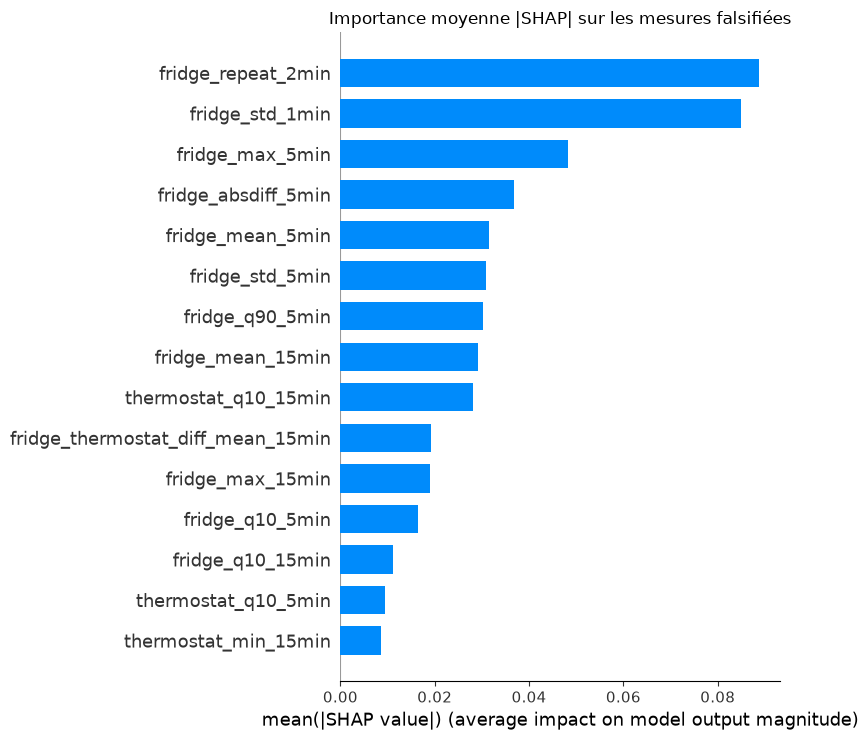

In [4]:
shap.summary_plot(sv, X[rows], feature_names=feats, plot_type="bar", max_display=15, show=False)
plt.title("Importance moyenne |SHAP| sur les mesures falsifiées"); plt.tight_layout(); plt.show()

### Étape 3b — Le même classement, mais avec le sens (beeswarm)

**Rôle de cette cellule :** montrer non seulement *combien* chaque feature compte, mais aussi *dans quel sens* elle agit.

Comment lire le graphique :

- chaque point = une mesure falsifiée parmi les 500 ;
- axe horizontal = contribution SHAP (à droite : pousse vers « attaque » ; à gauche : vers « normal ») ;
- couleur = valeur de la feature (rouge = valeur haute, bleu = valeur basse) ;
- les features sont triées de la plus influente (en haut) à la moins influente.

**Exemple :** si les points rouges de `fridge_repeat_2min` sont à droite, cela signifie « quand cette feature est élevée, le modèle penche vers attaque ». Si les points bleus sont à gauche, « quand elle est basse, le modèle penche vers normal ».

**À retenir :** le diagramme en barres dit « combien » ; celui-ci dit « combien et dans quel sens ». C'est le graphique le plus parlant pour un rapport.


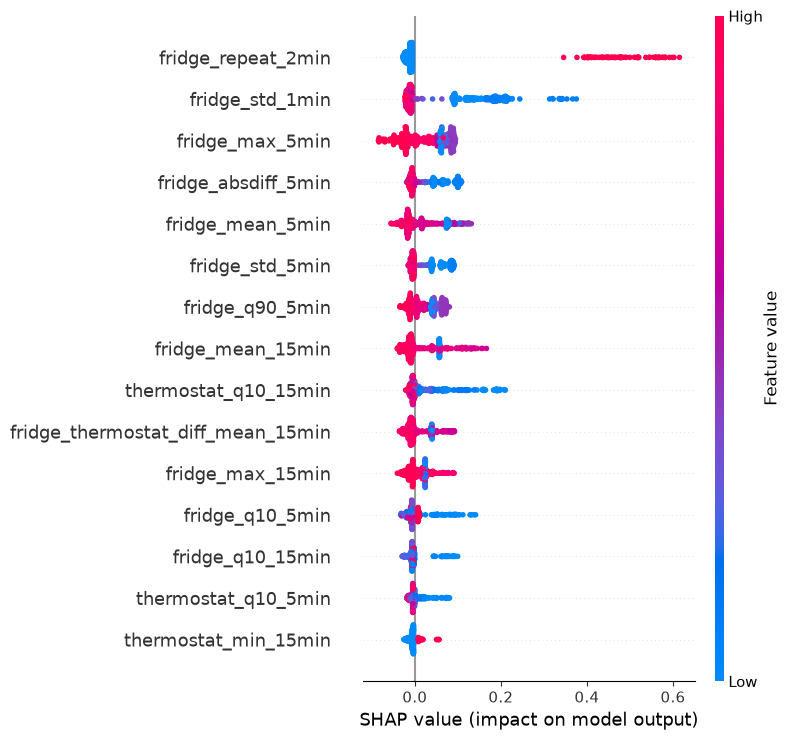

In [5]:
shap.summary_plot(sv, X[rows], feature_names=feats, max_display=15, show=False)
plt.tight_layout(); plt.show()

Lecture : chaque point est une mesure falsifiée ; à droite, la feature pousse vers « attaque » (rouge = valeur
haute de la feature, bleu = valeur basse).

## 4.2 Par scénario

### Étape 4 — Une explication par scénario d'attaque

**Rôle de cette cellule :** vérifier que le modèle ne détecte pas toutes les attaques de la même façon. Chaque scénario (gel, rejeu, biais, injection nominale, dérive...) a ses features caractéristiques.

- `imp = np.abs(sv)` : on reprend les importances absolues déjà calculées.
- `types[rows] == sc` : on sélectionne, parmi les 500, les mesures qui appartiennent au scénario `sc`.
- `moy = imp[m].mean(axis=0)` : importance moyenne de chaque feature pour ce scénario.
- `np.argsort(moy)[::-1][:4]` : les 4 features les plus importantes, de la plus forte à la plus faible.
- Le tableau final a une ligne par scénario et une colonne par rang (`feature 1` = la plus importante).

**À retenir :** un « rejeu » se repère par la répétition d'une même valeur (`fridge_repeat_2min`) ; un biais se repère par la **forme** de la distribution glissante (maximum, quantile bas), avant même que la moyenne ne bouge.


In [6]:
imp = np.abs(sv)
tab = {}
for sc in tr.ATTACK_NAMES:
    m = types[rows] == sc
    if m.any():
        moy = imp[m].mean(axis=0)
        top = np.argsort(moy)[::-1][:4]
        tab[sc] = {f"feature {i+1}": f"{feats[j]} ({moy[j]:.3f})" for i, j in enumerate(top)}
pd.DataFrame(tab).T

,feature 1,feature 2,feature 3,feature 4
MITM_gel,fridge_std_1min (0.121),fridge_max_5min (0.055),fridge_mean_5min (0.051),fridge_absdiff_5min (0.049)
MITM_rejeu,fridge_repeat_2min (0.276),thermostat_q10_15min (0.080),fridge_max_5min (0.027),thermostat_q10_5min (0.018)
Injection_nominale,fridge_std_1min (0.200),fridge_absdiff_5min (0.086),fridge_max_5min (0.077),fridge_std_5min (0.073)
Injection_biais_0.5,fridge_mean_15min (0.062),fridge_mean_5min (0.050),fridge_thermostat_diff_mean_15min (0.040),fridge_q10_5min (0.038)


### Étape 5 — Vérification croisée avec le script d'analyse

**Rôle de cette cellule :** comparer l'analyse rapide faite à l'écran (500 mesures, une seule répétition) avec l'analyse **cumulée** enregistrée par le script `transmission_study.py` sur toutes les rotations.

- `shap_transmission_reel.json` est un résultat déjà calculé et écrit sur le disque.
- Dans le fichier actuel : `n_lignes = 4 394` et `repetitions = 5`.
- Le tableau reprend les 4 features principales de chaque scénario, avec leur importance moyenne.

**À retenir :** si les deux tableaux se ressemblent (mêmes features en tête), l'explication est **stable** et ne dépend pas du tirage de 500 lignes. C'est un contrôle de robustesse, pas un nouveau calcul.


In [7]:
cumul = json.load(open(MODEL_DIR / "shap_transmission_reel.json", encoding="utf-8"))
print(f"Même analyse cumulée par le script ({cumul.get('modele', '')}, {cumul['n_lignes']:,} lignes, {cumul.get('repetitions')} rotations) :")
pd.DataFrame({sc: {f"feature {i+1}": f"{f['feature']} ({f['importance']:.3f})" for i, f in enumerate(lst[:4])}
              for sc, lst in cumul["par_scenario"].items()}).T

Même analyse cumulée par le script (ExtraTrees, 4,394 lignes, 5 rotations) :


,feature 1,feature 2,feature 3,feature 4
MITM_gel,fridge_std_1min (0.099),fridge_mean_5min (0.077),fridge_max_5min (0.053),fridge_mean_15min (0.053)
MITM_rejeu,fridge_repeat_2min (0.397),fridge_max_15min (0.026),thermostat_q10_15min (0.022),fridge_max_5min (0.020)
Injection_nominale,fridge_std_1min (0.169),fridge_max_5min (0.070),fridge_std_5min (0.069),fridge_absdiff_5min (0.066)
Injection_biais_0.5,fridge_max_5min (0.048),fridge_q10_5min (0.045),fridge_max_15min (0.043),fridge_mean_5min (0.037)
Injection_biais_1.0,fridge_mean_15min (0.070),fridge_q10_5min (0.065),fridge_max_5min (0.064),fridge_mean_5min (0.052)
Injection_biais_2.0,fridge_q10_5min (0.095),fridge_mean_5min (0.090),fridge_mean_15min (0.081),fridge_max_5min (0.067)
Injection_derive,fridge_q10_5min (0.072),fridge_max_5min (0.064),fridge_max_15min (0.047),fridge_mean_15min (0.042)
MITM_gel_thermostat,thermostat_std_1min (0.138),thermostat_std_5min (0.082),thermostat_absdiff_5min (0.075),fridge_thermostat_diff_mean_15min (0.035)


**Lecture des importances (Extra Trees).** Le drapeau `fridge_repeat_2min` porte la détection des rejeus ;
l'**écart-type sur 1 min** celle des gels et des valeurs forgées (trop régulières) ; les features de **forme de
la distribution glissante** (maximum et quantile 10 % sur 5 et 15 min) celle des biais et de la dérive : un
décalage de quelques dixièmes de degré déplace le haut et le bas de la distribution bornée du frigo (1–14 °C)
avant que la moyenne ne bouge. Pour le thermostat, ce sont ses propres écarts-types et sa variation absolue
moyenne.

## 4.3 Une mesure à la fois : pourquoi cette alerte ?

### Étape 6 — Expliquer une alerte précise, mesure par mesure

**Rôle de cette cellule :** passer de l'explication globale à l'explication d'**une seule mesure**, comme le ferait un opérateur devant une alerte.

La fonction `expliquer(scenario)` :

1. cherche, parmi les 500 mesures expliquées, celles du scénario demandé ;
2. prend celle du milieu (choix reproductible, pas de hasard) ;
3. garde ses 8 contributions SHAP les plus fortes en valeur absolue ;
4. trace des barres horizontales : rouge = pousse vers « attaque », bleu = pousse vers « normal » ;
5. affiche dans le titre le scénario, le numéro de ligne et le score du modèle (`predict_proba`, entre 0 et 1).

La boucle finale applique la fonction à 6 scénarios : `MITM_gel`, `MITM_rejeu`, `Injection_nominale`, `Injection_biais_0.5`, `Injection_biais_2.0`, `MITM_gel_thermostat`.

**À retenir :** c'est exactement ce que la page « Rapport d'alerte » du site montre à l'opérateur : « le modèle a alerté parce que ces 2 ou 3 features étaient anormales ». Si un scénario n'a aucune mesure hors entraînement, la fonction l'indique proprement au lieu de planter.


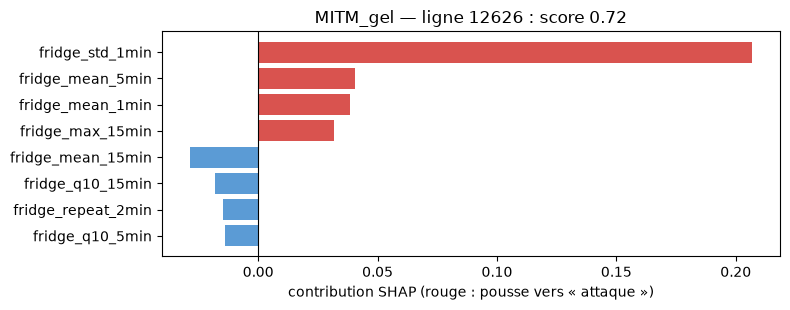

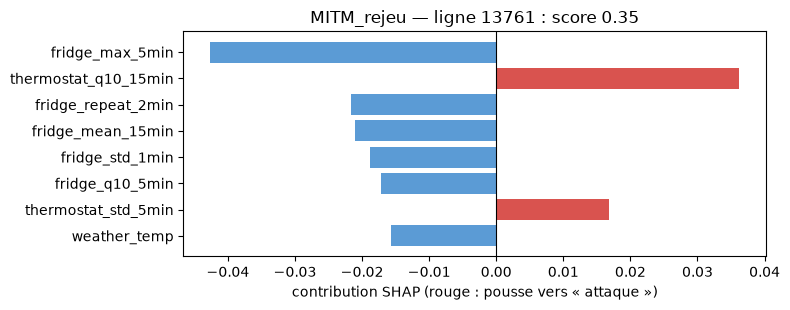

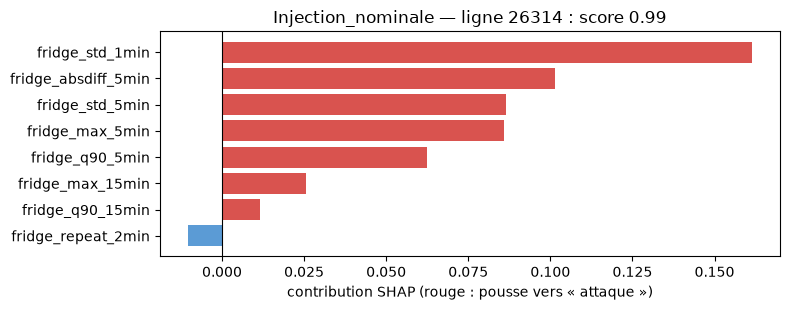

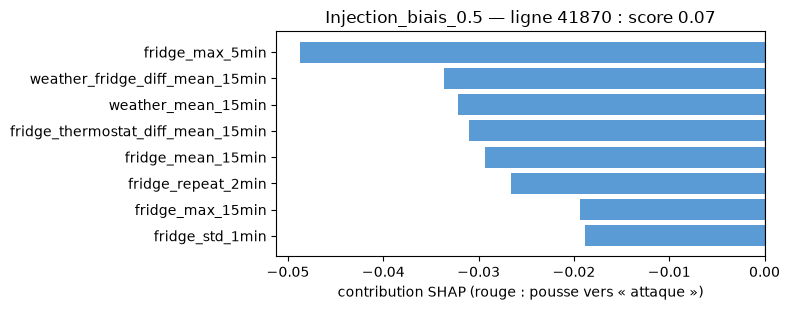

Injection_biais_2.0 : aucune mesure hors entraînement dans cette répétition
MITM_gel_thermostat : aucune mesure hors entraînement dans cette répétition


In [8]:
def expliquer(scenario, k=8):
    cand = [i for i, r in enumerate(rows) if types[r] == scenario]
    if not cand:
        print(scenario, ": aucune mesure hors entraînement dans cette répétition"); return
    i = cand[len(cand) // 2]
    contrib = pd.Series(sv[i], index=feats).sort_values(key=np.abs, ascending=False)[:k][::-1]
    plt.figure(figsize=(8, 3.2))
    plt.barh(contrib.index, contrib.values, color=np.where(contrib.values > 0, "#d9534f", "#5b9bd5"))
    plt.axvline(0, color="k", lw=0.8)
    plt.title(f"{scenario} — ligne {rows[i]} : score {model.predict_proba(X[[rows[i]]])[0, 1]:.2f}")
    plt.xlabel("contribution SHAP (rouge : pousse vers « attaque »)"); plt.tight_layout(); plt.show()

for sc in ("MITM_gel", "MITM_rejeu", "Injection_nominale", "Injection_biais_0.5", "Injection_biais_2.0", "MITM_gel_thermostat"):
    expliquer(sc)

Chaque alerte peut ainsi être justifiée à l'opérateur par deux ou trois features lisibles. C'est la base du
**rapport pour l'opérateur** (page « Rapport d'alerte » du site), qui reprend ces features par scénario.

## 4.4 Démonstration pas à pas : une seule mesure, de bout en bout

Cette section est **pédagogique** : elle ne produit aucun nouveau résultat pour le rapport. Elle reprend le modèle déjà chargé et **une seule** mesure, puis affiche dans l'ordre :

1. ce que **reçoit le modèle** (53 nombres) ;
2. ce que **répond le modèle** (2 probabilités) ;
3. ce que **reçoit SHAP** (le modèle + les 53 mêmes nombres) ;
4. ce que **répond SHAP** (53 morceaux, un par feature) ;
5. la **vérification** : `0,5 + somme des 53 morceaux = sortie du modèle`.

**À exécuter après les cellules 1 à 3** (il faut que `model`, `X`, `rows`, `feats` et `types` existent). La cellule choisit automatiquement l'attaque **la mieux détectée** parmi les 500 mesures expliquées, pour que l'exemple soit net.


In [ ]:
# =====================================================================
# DEMONSTRATION PAS A PAS : une seule mesure, du debut a la fin
# =====================================================================
# Aucun nouvel apprentissage : on reprend le modele deja charge et les
# valeurs SHAP deja calculees. On affiche simplement les 5 etapes.

explainer = shap.TreeExplainer(model)
base = float(np.ravel(explainer.expected_value)[-1])

# On choisit la mesure d'attaque que le modele detecte le plus fortement.
scores = model.predict_proba(X[rows])[:, 1]
k = int(np.argmax(scores))
ligne = rows[k]
x1 = X[[ligne]]                       # 1 ligne x 53 features

print("=" * 72)
print("ETAPE 1 - CE QUE RECOIT LE MODELE")
print("=" * 72)
print(f"Mesure choisie : ligne {ligne} du dataset, scenario {types[ligne]}")
print(f"Forme de l'entree : {x1.shape}  ->  1 ligne x {len(feats)} features")
print()
print("Les 5 premieres valeurs (il y en a 53 au total) :")
for f in feats[:5]:
    print(f"   {f:<26} = {x1[0, feats.index(f)]:>8.3f}")

print()
print("=" * 72)
print("ETAPE 2 - CE QUE REPOND LE MODELE")
print("=" * 72)
proba = model.predict_proba(x1)[0]
print(f"predict_proba  ->  [normal = {proba[0]:.4f} , attaque = {proba[1]:.4f}]")
print(f"Le modele dit : {proba[1] * 100:.1f} % de chance que ce soit une attaque.")
print("(Le seuil d'alerte du projet est 0,77, avec persistance 3 lignes sur 6.)")

print()
print("=" * 72)
print("ETAPE 3 - CE QUE RECOIT SHAP")
print("=" * 72)
print("SHAP recoit exactement 2 choses :")
print("   1) le modele deja entraine")
print("   2) la MEME ligne de 53 features que celle donnee au modele")
print(f"   Ici : model + une matrice de forme {x1.shape}")
print("SHAP ne recoit ni l'etiquette (y), ni la reponse du modele.")
print("Il recalcule lui-meme la reponse pour pouvoir la decouper.")

sv1 = explainer.shap_values(x1)
if isinstance(sv1, list):
    sv1 = sv1[-1]
sv1 = np.asarray(sv1)
if sv1.ndim == 3:
    sv1 = sv1[:, :, -1]               # contribution a la classe "attaque"
sv1 = sv1[0]                          # 53 contributions pour cette mesure
print(f"SHAP rend : {sv1.shape[0]} nombres (un par feature).")

print()
print("=" * 72)
print("ETAPE 4 - CE QUE REPOND SHAP")
print("=" * 72)
contrib = pd.Series(sv1, index=feats).sort_values(key=np.abs, ascending=False)
print("Les 10 contributions les plus fortes (en points de probabilite) :")
print(f"   {'feature':<34} {'valeur':>10} {'contribution':>14}")
for f, v in contrib.head(10).items():
    print(f"   {f:<34} {x1[0, feats.index(f)]:>10.3f} {v:>+14.4f}")
print(f"   {'... les 43 autres features':<34} {'':>10} {sv1.sum() - contrib.head(10).sum():>+14.4f}")
print(f"   {'TOTAL des 53 features':<34} {'':>10} {sv1.sum():>+14.4f}")

print()
print("=" * 72)
print("ETAPE 5 - LA VERIFICATION (le lien modele <-> SHAP)")
print("=" * 72)
print(f"point de depart (base)        : {base:+.4f}")
print(f"somme des 53 morceaux SHAP    : {sv1.sum():+.4f}")
print(f"base + somme                  : {base + sv1.sum():+.4f}")
print(f"predict_proba[attaque]        : {proba[1]:+.4f}")
print()
print("=> SHAP n'invente rien : il coupe la sortie du modele en 53 morceaux.")

# Petit graphique des 10 morceaux les plus importants.
top = contrib.head(10)[::-1]
plt.figure(figsize=(9, 3.4))
plt.barh(top.index, top.values, color=np.where(top.values > 0, "#d9534f", "#5b9bd5"))
plt.axvline(0, color="k", lw=0.8)
plt.title(f"Les 10 features qui fabriquent le score {proba[1]:.2f} (ligne {ligne})")
plt.xlabel("morceau de SHAP (rouge : pousse vers attaque, bleu : vers normal)")
plt.tight_layout()
plt.show()
